# Verify the rotation math

Simulates accelerometer readings for sensors A and B on the same rigid
segment, plots their axes in 3-D, and verifies R from `transform.py` maps
B's measurements into A's frame, gravity included.

No YAML or SMPL model needed -- sensors A and B are just two hand-picked
rotation matrices, not attached to a body mesh.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers the 3d projection)
from scipy.spatial.transform import Rotation

# world frame: Z up, gravity down
g_world = np.array([0.0, 0.0, -9.81])   # m/s^2

# accelerometer = specific force: a_measured = R_world_to_sensor @ (a_body - g_world)

def simulate_accel(R_world_to_sensor, a_body_world):
    """Return what a sensor measures given its mounting rotation and body accel."""
    return R_world_to_sensor @ (a_body_world - g_world)

In [2]:
# sensor A: flat, Z up (= world Z)
R_world_to_A = np.eye(3)

# sensor B: same wrist, twisted 45deg Y + 20deg Z relative to A
R_world_to_B = Rotation.from_euler("yz", [45, 20], degrees=True).as_matrix()

# relative rotation, same formula as transform.py (R_local.T = R_world_to_sensor)
R_A = R_world_to_A.T
R_B = R_world_to_B.T
R_rel = R_A.T @ R_B    # B's frame -> A's frame

## Visualize A and B's axes

A's axes (solid) line up exactly with the world axes -- in particular its Z
axis is the gravity axis, which is why the static scenario below puts all of
gravity on A's Z and nothing on X/Y. B's axes (dashed) are tilted, so the
same gravity magnitude spreads across all three.

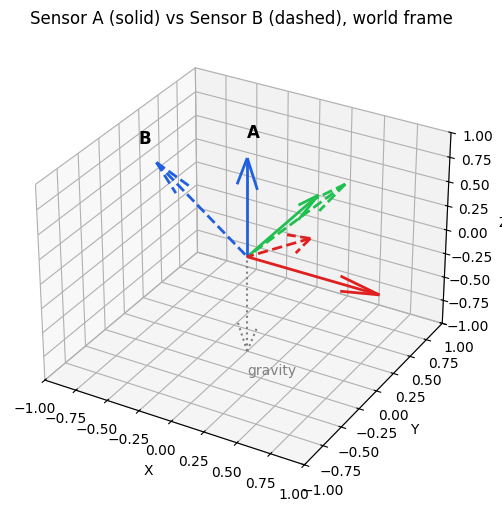

In [3]:
AXIS_COLORS = ["#e02020", "#20c050", "#2060e0"]  # X, Y, Z -- matches tool/smpl_loader.py

def plot_frame(ax, R_world_to_sensor, label, linestyle):
    """Draw a sensor's X/Y/Z axes as arrows from the origin. Columns of
    R_world_to_sensor.T (= R_sensor_to_world) are the sensor's axes in world coords."""
    R_sensor_to_world = R_world_to_sensor.T
    for i in range(3):
        vec = R_sensor_to_world[:, i]
        ax.quiver(0, 0, 0, *vec, color=AXIS_COLORS[i], linestyle=linestyle, linewidth=2, length=1.0)
    tip = R_sensor_to_world[:, 2] * 1.2
    ax.text(*tip, label, fontsize=12, weight="bold")

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="3d")

plot_frame(ax, R_world_to_A, "A", "solid")
plot_frame(ax, R_world_to_B, "B", "dashed")

grav_dir = g_world / np.linalg.norm(g_world)
ax.quiver(0, 0, 0, *grav_dir, color="gray", linewidth=1.5, linestyle="dotted", length=1.0)
ax.text(*(grav_dir * 1.25), "gravity", fontsize=10, color="gray")

ax.set_xlim([-1, 1]); ax.set_ylim([-1, 1]); ax.set_zlim([-1, 1])
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
ax.set_title("Sensor A (solid) vs Sensor B (dashed), world frame")
plt.show()

## Scenario 1: static body (no motion)

In [4]:
a_body = np.zeros(3)

a_A = simulate_accel(R_world_to_A, a_body)
a_B = simulate_accel(R_world_to_B, a_body)

print(f"Gravity in world frame :  {g_world}")
print()
print(f"Sensor A measures       :  {np.round(a_A, 4)}")
print(f"Sensor B measures       :  {np.round(a_B, 4)}")
print()
print("Both contain gravity, just expressed in different sensor axes.")
print("A is flat so it sees all gravity on Z: [0, 0, +9.81]")
print("B is tilted so gravity spreads across axes.")

print("Relative rotation R_rel (B's frame -> A's frame):")
print(np.round(R_rel, 4))
a_B_in_A = R_rel @ a_B
print()
print(f"R_rel @ B's measurement :  {np.round(a_B_in_A, 4)}")
print(f"A's measurement         :  {np.round(a_A, 4)}")
print(f"Match: {np.allclose(a_B_in_A, a_A)}")

Gravity in world frame :  [ 0.    0.   -9.81]

Sensor A measures       :  [0.   0.   9.81]
Sensor B measures       :  [6.5184 2.3725 6.9367]

Both contain gravity, just expressed in different sensor axes.
A is flat so it sees all gravity on Z: [0, 0, +9.81]
B is tilted so gravity spreads across axes.
Relative rotation R_rel (B's frame -> A's frame):
[[ 0.6645  0.2418 -0.7071]
 [-0.342   0.9397  0.    ]
 [ 0.6645  0.2418  0.7071]]

R_rel @ B's measurement :  [ 0.   -0.    9.81]
A's measurement         :  [0.   0.   9.81]
Match: True


## Scenario 2: arm moving (a_body = [2, 1, 3] m/s^2 in world)

In [5]:
a_body = np.array([2.0, 1.0, 3.0])

a_A = simulate_accel(R_world_to_A, a_body)
a_B = simulate_accel(R_world_to_B, a_body)

print(f"Sensor A measures       :  {np.round(a_A, 4)}  (linear accel + gravity)")
print(f"Sensor B measures       :  {np.round(a_B, 4)}  (linear accel + gravity)")

a_B_in_A = R_rel @ a_B
print()
print(f"R_rel @ B's measurement :  {np.round(a_B_in_A, 4)}")
print(f"A's measurement         :  {np.round(a_A, 4)}")
print(f"Match: {np.allclose(a_B_in_A, a_A)}")

Sensor A measures       :  [ 2.    1.   12.81]  (linear accel + gravity)
Sensor B measures       :  [9.4987 4.5214 7.6438]  (linear accel + gravity)

R_rel @ B's measurement :  [ 2.    1.   12.81]
A's measurement         :  [ 2.    1.   12.81]
Match: True


## Scenario 3: decompose into gravity and linear parts

In [6]:
g_in_A = R_world_to_A @ (-g_world)      # gravity component in A's frame
g_in_B = R_world_to_B @ (-g_world)      # gravity component in B's frame
lin_in_A = R_world_to_A @ a_body        # linear part in A's frame
lin_in_B = R_world_to_B @ a_body        # linear part in B's frame

print(f"Gravity in A's frame    :  {np.round(g_in_A, 4)}")
print(f"Gravity in B's frame    :  {np.round(g_in_B, 4)}")
print()
print(f"R_rel rotates B gravity :  {np.round(R_rel @ g_in_B, 4)}")
print(f"Should equal A gravity  :  {np.round(g_in_A, 4)}")
print(f"Match: {np.allclose(R_rel @ g_in_B, g_in_A)}")

print(f"Linear accel in A       :  {np.round(lin_in_A, 4)}")
print(f"Linear accel in B       :  {np.round(lin_in_B, 4)}")
print()
print(f"R_rel rotates B linear  :  {np.round(R_rel @ lin_in_B, 4)}")
print(f"Should equal A linear   :  {np.round(lin_in_A, 4)}")
print(f"Match: {np.allclose(R_rel @ lin_in_B, lin_in_A)}")

print()
print("Both gravity and linear components transform correctly.")
print("R distributes over addition: R@(g+lin) = R@g + R@lin.")
print("No need to remove gravity before applying R.")

Gravity in A's frame    :  [0.   0.   9.81]
Gravity in B's frame    :  [6.5184 2.3725 6.9367]

R_rel rotates B gravity :  [ 0.   -0.    9.81]
Should equal A gravity  :  [0.   0.   9.81]
Match: True
Linear accel in A       :  [2. 1. 3.]
Linear accel in B       :  [2.9803 2.1489 0.7071]

R_rel rotates B linear  :  [2. 1. 3.]
Should equal A linear   :  [2. 1. 3.]
Match: True

Both gravity and linear components transform correctly.
R distributes over addition: R@(g+lin) = R@g + R@lin.
No need to remove gravity before applying R.
